# Single Transmon - Grounded (xmon) flux lines 

We'll be creating a 2D design and adding a single transmon cross (xmon) qcomponent with flux lines.

Simple Metal Transmon Cross object. Creates the a cross-shaped island, the "junction" on the south end, and up to 3 connectors on the remaining arms (claw or gap).

'claw_width' and 'claw_gap' define the width/gap of the CPW line that makes up the connector. Note, DC SQUID currently represented by single inductance sheet

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/qiskit-community/qiskit-metal/blob/main/docs/circuit-examples/A.Qubits/05-Transmon_cross_fl.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/qiskit-community/qiskit-metal/main?labpath=docs%2Fcircuit-examples%2FA.Qubits%2F05-Transmon_cross_fl.ipynb)

> 💡 **Running in Colab or Binder?** Skip the desktop GUI install — the cell below grabs the lite (no-Qt) wheel, and `qm.gui(design)` auto-picks an inline matplotlib viewer with the same API (`gui.rebuild()`, `gui.screenshot()`, `gui.edit_component(...)`) as the desktop `MetalGUI`.

In [1]:
# In Colab / Binder, uncomment to install Quantum Metal (lite, no Qt).
# Locally you should already have it via `pip install quantum-metal` or
# `pip install 'quantum-metal[gui]'` for the desktop GUI.
# !pip install -q quantum-metal

> 💡 **Using this tutorial without the Qt GUI**
> 
> This tutorial uses the desktop `MetalGUI`. To follow along on Colab, Binder, JupyterHub, or any environment where Qt isn't available, **replace any `gui.rebuild()` / `gui.screenshot()` call with `qm.view(design)`** — it renders the design to a matplotlib `Figure` you can display inline or save with `fig.savefig(...)`.
> 
> See [1.1 Quick start](https://qiskit-community.github.io/qiskit-metal/tut/1-Overview/1.1-Quick-start.html) for a complete runnable walkthrough and [`docs/headless-usage.rst`](https://qiskit-community.github.io/qiskit-metal/headless-usage.html) for the full reference.

> **Note on this executed copy:** run with Quantum Metal 0.9.0 (PyPI `quantum-metal`, import name `qiskit_metal`) on Python 3.10 without the Qt GUI. Only the viewer calls were adapted (`MetalGUI(design)` -> `qm.gui(design)` inline viewer, guarded close), exactly as the tutorial's own headless note above describes. The design code, options and geometry are unchanged from the official tutorial. This tutorial builds the 2D layout only - no EM simulation or parameter extraction is run here.

In [2]:
import qiskit_metal as qm
import qiskit_metal as metal
from qiskit_metal import designs, draw
from qiskit_metal import Dict, open_docs

# Headless adaptation: the desktop MetalGUI needs the optional Qt extras (PySide6).
# qm.gui(design) auto-picks an inline matplotlib viewer when Qt is unavailable.

In [3]:
# Each time you create a new quantum circuit design,
# you start by instantiating a QDesign class.

# The design class `DesignPlanar` is best for 2D circuit designs.

design = designs.DesignPlanar()

10:41PM 56s INFO [_start_renderers]: Renderer=hfss skipped: runtime dependency not installed (QAnsysRenderer requires pyEPR. Install with: pip install 'quantum-metal[ansys]').


10:41PM 56s INFO [_start_renderers]: Renderer=q3d skipped: runtime dependency not installed (QAnsysRenderer requires pyEPR. Install with: pip install 'quantum-metal[ansys]').


10:41PM 56s INFO [_start_renderers]: Renderer=gmsh skipped: runtime dependency not installed (renderer_gmsh requires gmsh. Install with: pip install 'quantum-metal[mesh]' (or the legacy alias 'quantum-metal[fem]')).


10:41PM 56s INFO [_start_renderers]: Renderer=aedt_q3d skipped: runtime dependency not installed (QPyaedt requires pyaedt (ansys.aedt.core). Install with: pip install 'quantum-metal[ansys]').


10:41PM 56s INFO [_start_renderers]: Renderer=aedt_hfss skipped: runtime dependency not installed (QPyaedt requires pyaedt (ansys.aedt.core). Install with: pip install 'quantum-metal[ansys]').


In [4]:
# Launch the design viewer. On a desktop with the Qt extras this would be MetalGUI(design);
# qm.gui(design) auto-picks the headless inline matplotlib viewer here.
gui = qm.gui(design)

### A transmon qubit with flux lines
You can create a ready-made transmon cross qubit with flux lines from the QComponent Library, `qiskit_metal.qlibrary.qubits`. 
`transmon_cross_fl.py` is the file containing our qubit so `transmon_cross_fl` is the module we import. 
The `TransmonCrossFL` class is our transmon cross qubit. Like all quantum components, `TransmonCrossFL` inherits from `QComponent`. 

 Connector lines can be added using the `connection_pads` dictionary. 
 Each connector pad has a name and a list of default properties.

In [5]:
from qiskit_metal.qlibrary.qubits.transmon_cross_fl import TransmonCrossFL

# Be aware of the default_options that can be overridden by user.
TransmonCrossFL.get_template_options(design)

{'pos_x': '0.0um',
 'pos_y': '0.0um',
 'orientation': '0.0',
 'chip': 'main',
 'layer': '1',
 'connection_pads': {},
 '_default_connection_pads': {'connector_type': '0',
  'claw_length': '30um',
  'ground_spacing': '5um',
  'ground_spacing_back': None,
  'claw_width': '10um',
  'claw_width_back': None,
  'claw_gap': '6um',
  'claw_cpw_length': '40um',
  'claw_cpw_width': '10um',
  'connector_location': '0'},
 'cross_width': '20um',
 'cross_length': '200um',
 'cross_gap': '20um',
 'make_fl': True,
 'fl_options': {'t_top': '15um',
  't_offset': '0um',
  't_inductive_gap': '3um',
  't_width': '5um',
  't_gap': '3um'},
 'gds_cell_name': 'my_other_junction'}

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


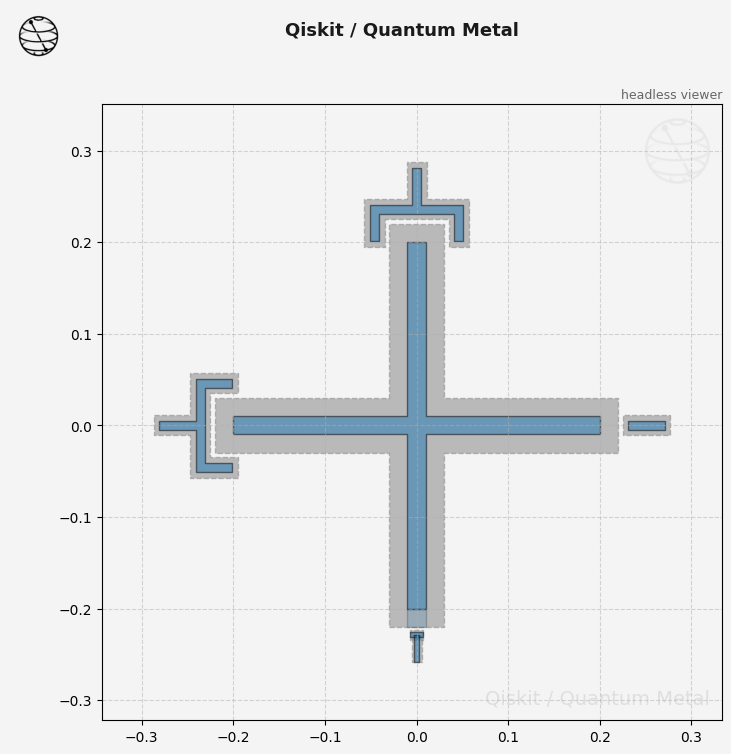

In [6]:
# The connectord_type can be string of '0' for 'Claw' or '1' for 'Gap'
# to define which type of connector is used.

# The connector_location can be a string of '0', '90', '180' or '270' degrees,
# selecting the west, north, east or south arm for a given connector.
# South ('270') carries both the junction and the flux line, so a connector
# placed there overlaps the flux line - TransmonCrossFL warns when you do.

xmon_options = dict(
    connection_pads=dict(
        a=dict(connector_location="0", connector_type="0"),
        b=dict(connector_location="90", connector_type="0"),
        c=dict(connector_location="180", connector_type="1"),
    ),
)

# Create a new Transmon Cross object with name 'Q1'
q1 = TransmonCrossFL(design, "Q1", options=xmon_options)

gui.rebuild()  # rebuild the design and plot
gui.autoscale()  # resize GUI to see QComponent
gui.zoom_on_components(["Q1"])  # Can also gui.zoom_on_components([q1.name])

option,value,parsed,description
pos_x,'0.0um',0.0,The x/y position of the center of the QComponent.
pos_y,'0.0um',0.0,The x/y position of the center of the QComponent.
orientation,'0.0',0.0,The primary direction in degrees of the QComponent. Expressed counter-clockwise orientation.
chip,'main','main',Chip holding the QComponent.
layer,'1',1.0,Manufacturing layer used for the QComponent.
connection_pads,,,The dictionary which contains all active connection lines for the qubit.
a,,,
connector_type,'0',0.0,"0 = Claw type, 1 = gap type"
claw_length,'30um',0.03,"Length of the claw 'arms', measured from the connector center trace"
ground_spacing,'5um',0.005,Amount of ground plane between the connector and Crossmon arm (minimum should be based on fabrication capabilities)

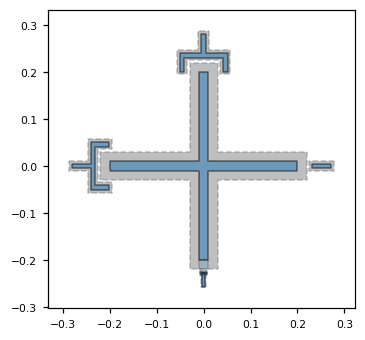

In [7]:
# Let's see what the Q1 object looks like
q1  # print Q1 information

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


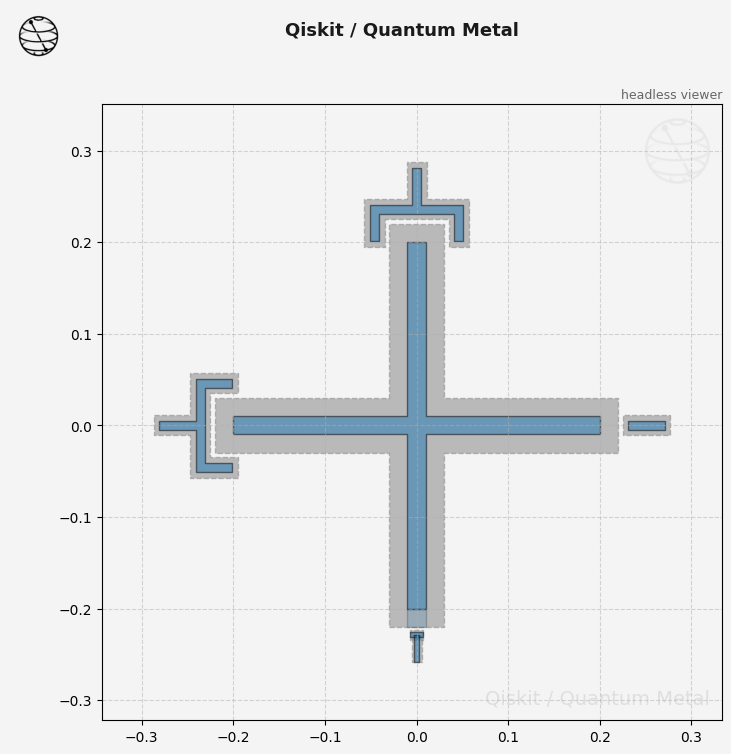

In [8]:
# Save screenshot as a .png formatted file.

gui.screenshot()

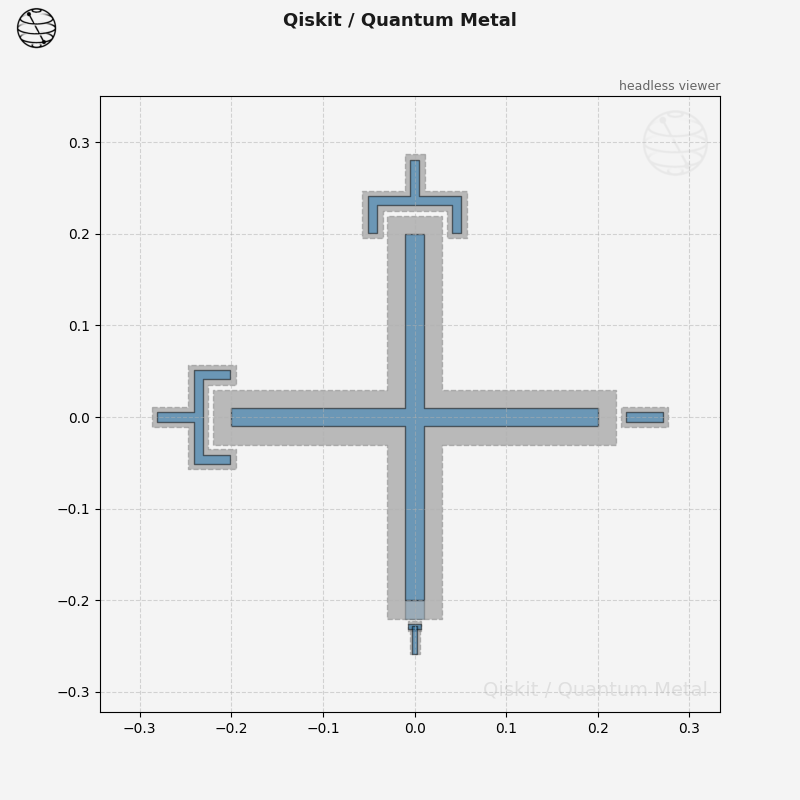

In [9]:
# Screenshot the canvas only as a .png formatted file.
gui.figure.savefig("shot.png")

from IPython.display import Image, display

_disp_ops = dict(width=500)
display(Image("shot.png", **_disp_ops))

## Closing the Qiskit Metal GUI

In [10]:
# Desktop Qt GUI: gui.main_window.close().
# The headless inline viewer has no Qt window to close, so guard it.
try:
    gui.main_window.close()
except AttributeError:
    pass

## Extra (not part of the official tutorial)
Export the finished layout to a GDS file, e.g. for fabrication workflows or import into EM tools.

In [11]:
from qiskit_metal.renderers.renderer_gds.gds_renderer import QGDSRenderer

gds_renderer = QGDSRenderer(design)
gds_renderer.export_to_gds("xmon_fluxline.gds")
print("GDS written: xmon_fluxline.gds")

10:41PM 57s WARNING [import_junction_gds_file]: Not able to find file:"../resources/Fake_Junctions.GDS".  Not used to replace junction. Checked directory:"/downloads/resources".


GDS written: xmon_fluxline.gds
